# Seaborn ile Doğrusal Regresyon

🚀 Seaborn kullanarak Doğrusal Regresyon analizine görsel olarak başlayalım!

Hedefimiz aşağıdakilerin ilk anlayışını elde etmektir:
- `orders` özelikleri ve
- onlarla ilişkili `review_scores`

In [1]:
import sys
print(sys.executable)

/home/turke/.pyenv/versions/workintech/bin/python


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# Import Modules
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

⚠️ Devam etmeden önce:
* 💾 Önceki ünitenin Orders challenge'ının çözümünü indirin
* 👥 `order_solution.py` dosyasının içeriğini `olist/order.py` dosyanıza kopyala-yapıştır yapın

⚠️ `olist` deponuzda `order.py` dosyasındaki kod değişikliklerini commit etmeyi unutmayın!

👇 Öncelikle `orders` veri setini içeri aktarın

In [4]:
import olist.order

print(olist.order.__file__)

/home/turke/code/data-context-and-setup/olist/order.py


In [5]:
import importlib
import olist.order

importlib.reload(olist.order)

Order = olist.order.Order

print(hasattr(Order, "get_training_data"))

True


In [6]:
import importlib
import olist.order

importlib.reload(olist.order)

Order = olist.order.Order

print(hasattr(Order, "get_training_data"))

True


In [12]:
from olist.order import Order

orders = Order().get_training_data(
    with_distance_seller_customer=False
)

orders.head()

,order_id,wait_time,expected_wait_time,delay_vs_expected,order_status,dim_is_five_star,dim_is_one_star,review_score,number_of_items,number_of_sellers,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,15.544063,0.0,delivered,0.0,0.0,4.0,1,1,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,19.137766,0.0,delivered,0.0,0.0,4.0,1,1,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,26.639711,0.0,delivered,1.0,0.0,5.0,1,1,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,26.188819,0.0,delivered,1.0,0.0,5.0,1,1,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,12.112049,0.0,delivered,1.0,0.0,5.0,1,1,19.90,8.72


In [7]:
import sys

sys.path.insert(0, "/home/turke/code/data-context-and-setup")

from olist.order import Order

orders = Order().get_training_data(
    with_distance_seller_customer=False
)

orders.head()

,order_id,wait_time,expected_wait_time,delay_vs_expected,order_status,dim_is_five_star,dim_is_one_star,review_score,number_of_items,number_of_sellers,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,15.544063,0.0,delivered,0.0,0.0,4.0,1,1,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,19.137766,0.0,delivered,0.0,0.0,4.0,1,1,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,26.639711,0.0,delivered,1.0,0.0,5.0,1,1,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,26.188819,0.0,delivered,1.0,0.0,5.0,1,1,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,12.112049,0.0,delivered,1.0,0.0,5.0,1,1,19.90,8.72


## 1 - Özellik Korelasyonunu İnceleme

❓Özellikler arasındaki çeşitli korelasyonları inceleyin: hangi özellik `review_score` ile en çok korelasyonlu görünüyor?

<details>
    <summary>▸ İpucu</summary>

* `DataFrame.corr(numeric_only=True)` kullanın `sns.heatmap()` ve `cmap='coolwarm'` ile kombinasyon yaparak
* `review_score` ile her bir özellik arasındaki korelasyon katsayılarının mutlak değerlerine bakın,
    * katsayı ne kadar yüksekse, verilen özellik `review_score` ile o kadar çok korelasyonludur (pozitif veya negatif)

</details>

In [13]:
# Sayısal değişkenler arasındaki korelasyon matrisi
corr_matrix = orders.select_dtypes(include="number").corr()

# review_score ile korelasyonları sıralayalım
corr_matrix["review_score"].sort_values()

dim_is_one_star      -0.807700
wait_time            -0.333758
delay_vs_expected    -0.272281
number_of_items      -0.123492
number_of_sellers    -0.116942
freight_value        -0.090013
expected_wait_time   -0.052410
price                -0.034742
dim_is_five_star      0.791787
review_score          1.000000
Name: review_score, dtype: float64

* 😏 _Kaptan Açık :_
    * `review_score` kendisiyle %100 korelasyonludur
    * ve `dim_is_one_star` ve `dim_is_five_star` ile güçlü korelasyonludur...
* ⚠️ `review_score` ile ilgili sonraki iki en yüksek korelasyon katsayısı :
    * `wait_time` : - %34
    * `delay_vs_expected` : - %27

## 2. `review_score` ile teslimat süresi arasında Doğrusal Regresyon

👉 Görünüşe göre `review_score` çoğunlukla `wait_time` (= - %34) ve `delay_vs_expected` (- %27) ile korelasyonludur.

🎨 Bu korelasyonları `seaborn` ile araştıralım

### 2.1 Grafikler
❓ Sırasıyla `review_score` ile `wait_time` ve `delay_vs_expected` arasında regresyon yapan 2 grafik oluşturun.

<u>İpuçları</u>:

- Hız açısından veri çerçevesini rastgele bir `10.000 satırlık örneğe` indirin (veri keşiflemede iyi bir uygulama)
- Gerekirse her yürütmede örneği değiştirilmekten kaçınmak için `DataFrame.sample()` sabit bir `random_state` ile kullanın
- Regresyon `lines` çizmek için `sns.regplot()` kullanın
- Saçılım grafiğinin yoğunluğunu daha iyi görselleştirmek için bazı `y_jitter` parametreleri ekleyin
- `sns.regplot()` hemen sonrasına bunu ekleyerek `xlim` ve `ylim` sınırlayın (aynı hücrede):
  ```python
  plt.xlim(right=70)
  plt.ylim(bottom=0)
  ```

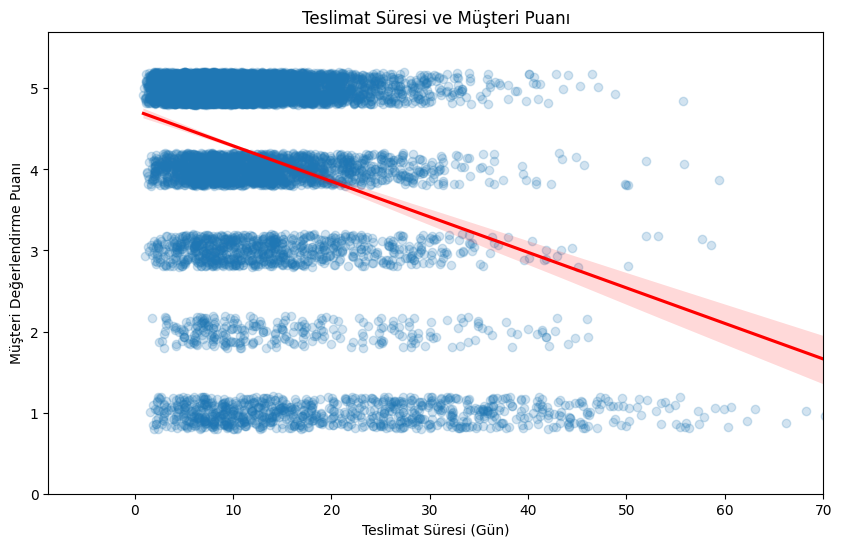

In [14]:
# Rastgele 10.000 sipariş seçelim
sample_orders = orders.sample(n=10000, random_state=42)

# Teslimat süresi ve müşteri puanı ilişkisi
plt.figure(figsize=(10, 6))

sns.regplot(
    data=sample_orders,
    x="wait_time",
    y="review_score",
    y_jitter=0.2,
    scatter_kws={"alpha": 0.2},
    line_kws={"color": "red"}
)

plt.title("Teslimat Süresi ve Müşteri Puanı")
plt.xlabel("Teslimat Süresi (Gün)")
plt.ylabel("Müşteri Değerlendirme Puanı")

plt.xlim(right=70)
plt.ylim(bottom=0)

plt.show()

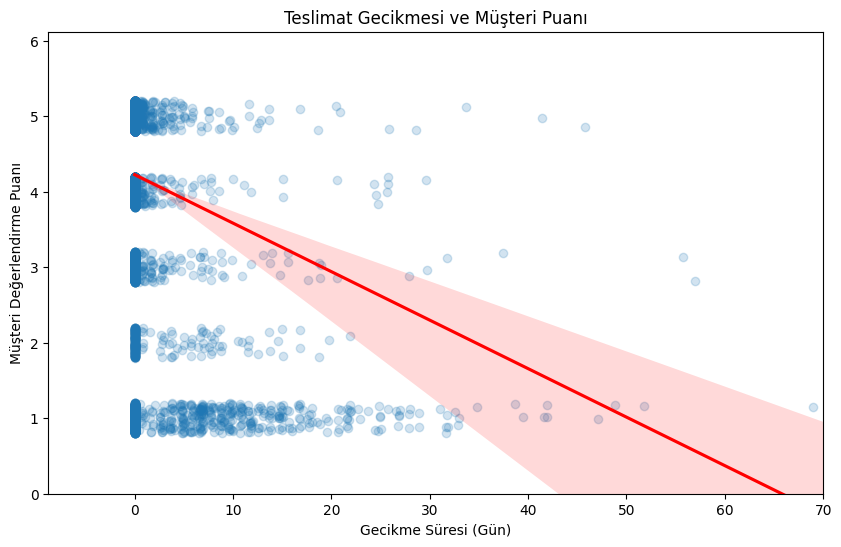

In [15]:
# Gecikme süresi ve müşteri puanı ilişkisi
plt.figure(figsize=(10, 6))

sns.regplot(
    data=sample_orders,
    x="delay_vs_expected",
    y="review_score",
    y_jitter=0.2,
    scatter_kws={"alpha": 0.2},
    line_kws={"color": "red"}
)

plt.title("Teslimat Gecikmesi ve Müşteri Puanı")
plt.xlabel("Gecikme Süresi (Gün)")
plt.ylabel("Müşteri Değerlendirme Puanı")

plt.xlim(right=70)
plt.ylim(bottom=0)

plt.show()

ℹ️ `regplot` ne yaptı ? 

👉 `review_score` ile `wait_time` ve `delay_vs_exp` arasında `Doğrusal Regresyon` yapmaya çalıştı

🧐 Pek yorumlanabilir görünmüyor, değil mi ?

👉 Haklısınız: sadece 5 farklı review skoru vardır ve bunlar beş farklı olası değeri olan kategorisel bir değişken olarak yorumlanabilir (örneğin: "çok kötü", "kötü", "orta", "iyi" ve "çok iyi") ve `wait_time` ve `delay_vs_exp` olan iki sürekli değere karşı regresyon yapmaya çalışıyoruz.

👀 Ancak regresyon çizgilerine göre çok sezgisel bir desen görebiliriz: bekleme süresi ve/veya gecikme ne kadar uzunsa, review skoru o kadar düşüktür - şaşırtıcı değil. Ama review skoru ne kadar hızlı düşüyor ?

### 2.2 Yorumlama

❓Her eğrinin `eğimini` görsel olarak "hesaplamaya" çalışın. 

✍️ Bu katsayıları veri eğitimi almamış bir kitleye açıklamış olsaydınız, bunları nasıl yorumlayacağınızı yazın.

In [16]:
import numpy as np

slope_wait = np.polyfit(
    sample_orders["wait_time"],
    sample_orders["review_score"],
    1
)[0]

slope_delay = np.polyfit(
    sample_orders["delay_vs_expected"],
    sample_orders["review_score"],
    1
)[0]

print("Teslimat süresi eğimi:", slope_wait)
print("Gecikme süresi eğimi:", slope_delay)

Teslimat süresi eğimi: -0.04380266996695329
Gecikme süresi eğimi: -0.06420665418084127


<details>
    <summary>Cevap</summary>

- `Slope wait_time ≈ -0.05` : "Bir sipariş teslim edilmesi için beklenen her ek gün için, review skoru ortalama olarak 0.05 azalır"
- `Slope delay ≈ -0.1` : "Bir sipariş _beklenen teslimat tarihinden sonra_ teslim edilmesi için her ek gün, review skoru ortalama olarak 0.1 azalır"

❓ Gecikmenin bekleme süresinden daha etkileyici görünmesine şaşırdınız mı? 

👉 Siparişinizi almak için sabırsız olabilirsiniz ve kısa bir bekleme süresi istersiniz, ancak paketinizi beklenen teslimat tarihinden sonra almaktan daha da hayal kırıklığına uğrarsınız!

</details>

**Regresyon Eğimlerinin Yorumlanması**

Olist sipariş verileri üzerinde yapılan doğrusal regresyon analizinde iki değişkenin de müşteri değerlendirme puanlarıyla negatif ilişkili olduğu görülmüştür.

- **Teslimat süresi (wait_time):** Regresyon eğimi yaklaşık -0.044'tür. Teslimat süresindeki her 1 günlük artış, müşteri puanında ortalama 0.044 puanlık azalmayla ilişkilidir.
- **Teslimat gecikmesi (delay_vs_expected):** Regresyon eğimi yaklaşık -0.064'tür. Beklenen teslimat tarihinden sonraki her 1 günlük ek gecikme, müşteri puanında ortalama 0.064 puanlık azalmayla ilişkilidir.

Bu sonuçlar, teslimat gecikmelerinin müşteri memnuniyetiyle olumsuz ilişkili olduğunu göstermektedir. Ancak korelasyon ve regresyon ilişkileri tek başına nedensellik kanıtlamaz.

### 2.3 Çıkarımsal Analiz

Bu regplotlar için 100.000 siparişin tamamını kullansak bile, bu siparişler sonuçta sadece 16 ayın verilerini temsil eder...

⚠️⚠️⚠️ Bu katsayıların **istatistiksel olarak anlamlı** olduğundan **ne kadar emin** olduğumuz? ⚠️⚠️⚠️

⚡️ Bu katsayıların istatistiksel anlamlılığı hakkında sorular:

* Bu katsayılar gelecekteki siparişlere iyi bir şekilde genelleştirilebilir mi (diğer her şey eşit olarak) ? (*İdeal cevap: Evet*) 
* Bu katsayıların sınırlı gözlem döneminden kaynaklanan rastgele dalgalanmalar yakalamadığından emin miyiz ? (*İdeal cevap: Hayır*) 

🧐 Bu iki eğim için ortalama değer etrafında **`güven aralığını`** tahmin etmemiz gerekir  :
$$slope_{wait} = -0.05 ± \ ?? \ \text{[%95 aralık]} $$
$$slope_{delay} = -0.1 ± \ ?? \ \text{[%95 aralık]} $$

⭐️ Neyse ki, `Seaborn` bu %95 güven aralığını regresyon çizgisinin etrafında gölgeli bir mavi koni ile zaten hesaplamıştır!

❓`Seaborn` `regplot` yeniden kullanarak iki güven aralığını görselleştirin:
- Örnek veri setinizin `boyutunu değiştirin`: 
    - Örnek boyutu küçüldükçe eğimin nasıl değiştiğine dikkat edin. 
    - Güven aralığı hakkında ne dersiniz?
- `ci` adlı regplot parametresi ile oynayarak `güven aralığının boyutunu` değiştirin (%95 varsayılan)

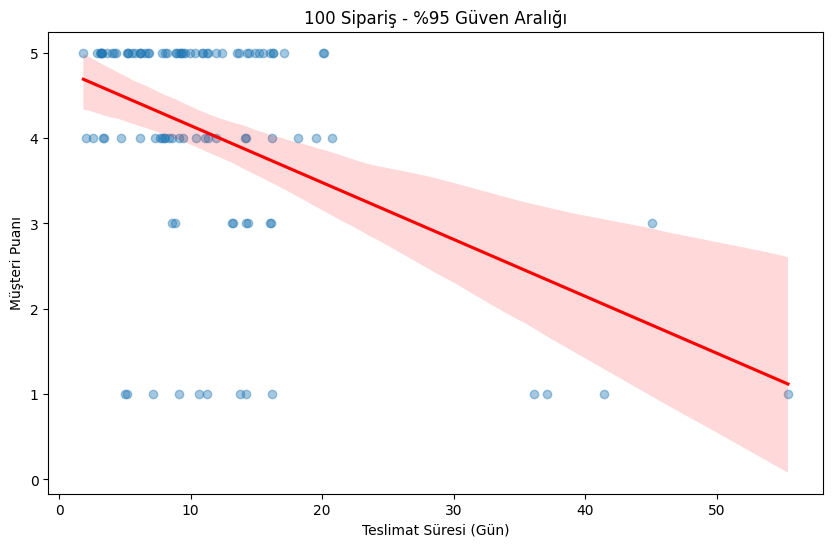

In [17]:
small_sample = orders.sample(n=100, random_state=42)

plt.figure(figsize=(10, 6))

sns.regplot(
    data=small_sample,
    x="wait_time",
    y="review_score",
    ci=95,
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title("100 Sipariş - %95 Güven Aralığı")
plt.xlabel("Teslimat Süresi (Gün)")
plt.ylabel("Müşteri Puanı")

plt.show()

🔎 Yorumlama:

* **Boş Hipotez** $H_0$ : "bu değişken review skoru etkilemez", yani katsayısı sıfıra eşittir

Tüm veri noktalarımızı çizdiğimizde:
- Eğim için %95 güven aralığı 0 değerini içermez.
    - 👉 `Daha yavaş teslimatların daha zayıf yorumlarla ilişkili olduğundan %95 emin`.
- "Teslimat süresinin review skorları üzerindeki etkisi hemen hemen sıfırdır" boş hipotezi ile ilişkili **`p-değeri`** %5'ten düşüktür
    - 👉 Bu boş hipotezi güvenle reddedebilir ve **`alternatif hipotez`** = `"teslimat süresi review skoru üzerinde etkiye sahiptir"` düşünebiliriz

🔥 Bulguşlarımızın **istatistiksel olarak anlamlı** olduğu söylenir. 

⚠️ Ancak, **korelasyon nedensellik anlamına gelmez**. 

- Belirli ürünlerin teslimatı doğal olarak daha yavaş olabilir (örn. ağır ürünler)
    - Bu ürün kategorileri, teslimat sürelerinin ne kadar uzun olursa olsun, genellikle düşük review_score'a sahip olacaktır. 

👉 **Karıştırıcı faktörleri** tanımlamak çok önemlidir ve basit bir tek değişkenli regresyon ile yapılamaz. 

</details>

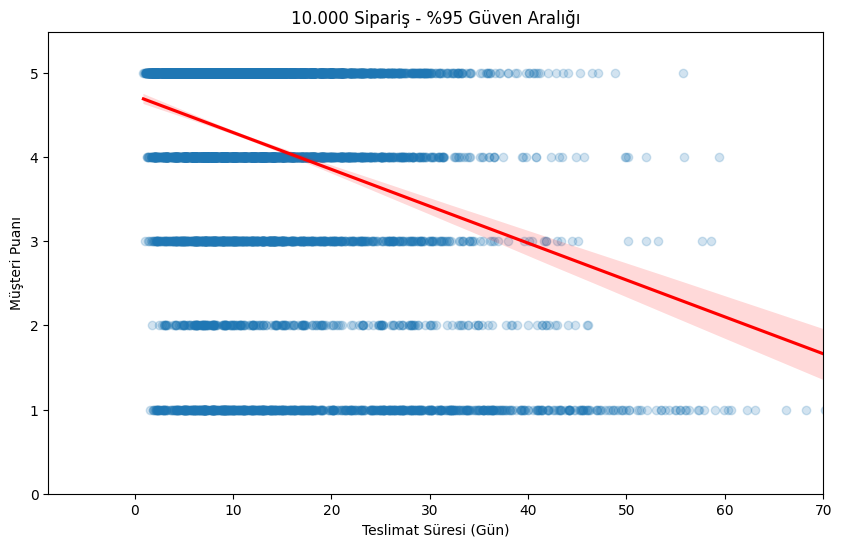

In [18]:
large_sample = orders.sample(n=10000, random_state=42)

plt.figure(figsize=(10, 6))

sns.regplot(
    data=large_sample,
    x="wait_time",
    y="review_score",
    ci=95,
    scatter_kws={"alpha": 0.2},
    line_kws={"color": "red"}
)

plt.title("10.000 Sipariş - %95 Güven Aralığı")
plt.xlabel("Teslimat Süresi (Gün)")
plt.ylabel("Müşteri Puanı")

plt.xlim(right=70)
plt.ylim(bottom=0)

plt.show()

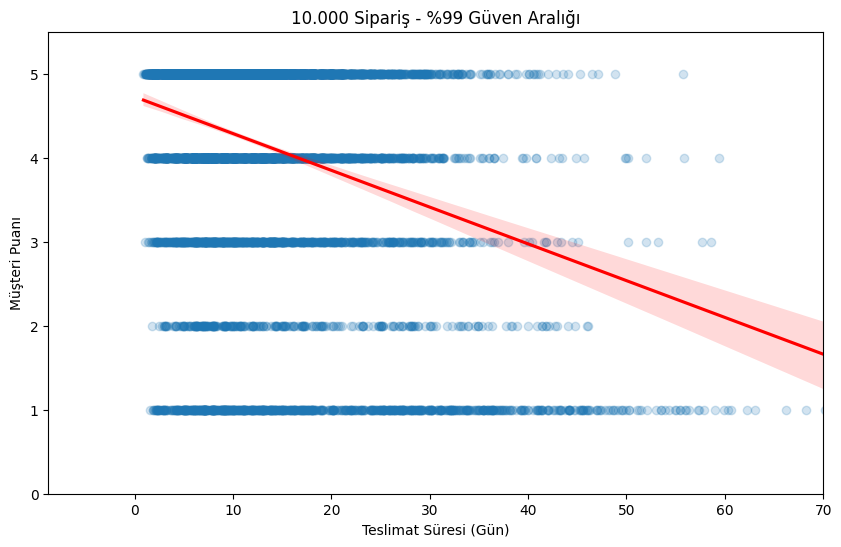

In [19]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=large_sample,
    x="wait_time",
    y="review_score",
    ci=99,
    scatter_kws={"alpha": 0.2},
    line_kws={"color": "red"}
)

plt.title("10.000 Sipariş - %99 Güven Aralığı")
plt.xlabel("Teslimat Süresi (Gün)")
plt.ylabel("Müşteri Puanı")

plt.xlim(right=70)
plt.ylim(bottom=0)

plt.show()

In [20]:
import statsmodels.api as sm

# Teslimat süresi regresyonu
X_wait = sm.add_constant(orders["wait_time"])
y = orders["review_score"]

model_wait = sm.OLS(y, X_wait).fit()

# Gecikme süresi regresyonu
X_delay = sm.add_constant(orders["delay_vs_expected"])

model_delay = sm.OLS(y, X_delay).fit()

# Sonuçları göster
print("Teslimat Süresi:")
print(model_wait.summary())

print("\nGecikme Süresi:")
print(model_delay.summary())

Teslimat Süresi:
                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.111
Model:                            OLS   Adj. R-squared:                  0.111
Method:                 Least Squares   F-statistic:                 1.208e+04
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:55:12   Log-Likelihood:            -1.5519e+05
No. Observations:               96353   AIC:                         3.104e+05
Df Residuals:                   96351   BIC:                         3.104e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.7236      0.006   

In [21]:
print("Gecikme süresi eğimi:")
print(model_delay.params)

print("\nP-değerleri:")
print(model_delay.pvalues)

print("\n%95 güven aralıkları:")
print(model_delay.conf_int())

Gecikme süresi eğimi:
const                4.212409
delay_vs_expected   -0.075137
dtype: float64

P-değerleri:
const                0.0
delay_vs_expected    0.0
dtype: float64

%95 güven aralıkları:
                          0         1
const              4.204500  4.220318
delay_vs_expected -0.076814 -0.073461


---
🏁 Tebrikler! 

🙏 Notebook'unuzu `commit` ve `push` etmeyi unutmayın